# Ecuación de Poisson comóvil en 2D — LFIS428, Grupo 3

Este cuaderno compila, valida y usa el código `src/poisson_comovil_cpu.c`, la versión periódica (cosmológica) del código de referencia del curso. Contenido:

1. Resumen de la física
2. El código C periódico
3. Validación con un modo exacto
4. Número de iteraciones frente a la teoría
5. Campo cosmológico: densidad, potencial y espectros
6. Para qué sirve: simulación *particle-mesh* 2D
7. Siguiente paso: CUDA

Las figuras se guardan en `figuras/` (PNG y PDF) para el README y el informe. Los números entre corchetes remiten a las referencias al final.

**Cómo correrlo.** El cuaderno es autocontenido: el código C está escrito en las celdas de la sección 2, que lo guardan en `salidas/poisson_comovil_cpu.c` antes de compilarlo.

- **Google Colab:** *Archivo → Subir cuaderno* y *Entorno de ejecución → Ejecutar todas*. Colab ya trae `gcc`, `numpy` y `matplotlib`; las figuras quedan en la carpeta `figuras/` del panel de archivos.
- **VS Code / Jupyter local:** ábrelo desde la carpeta `notebooks/` del repositorio; las figuras se guardan en `figuras/` de la raíz y el cuaderno verifica que su código coincida con `src/poisson_comovil_cpu.c`.

In [1]:
import os, re, shutil, subprocess, time, filecmp
import numpy as np
import matplotlib.pyplot as plt

plt.rcParams.update({"figure.dpi": 110, "font.size": 11, "savefig.bbox": "tight"})

# Dentro del repositorio (notebooks/) las figuras van a ../figuras; en Colab, a ./figuras
EN_REPO = os.path.exists(os.path.join("..", "src", "poisson_comovil_cpu.c"))
FIG = os.path.abspath(os.path.join("..", "figuras") if EN_REPO else "figuras")
TRABAJO = os.path.abspath("salidas")          # código, ejecutable y datos temporales (ignorados por git)
os.makedirs(FIG, exist_ok=True)
os.makedirs(TRABAJO, exist_ok=True)

def guardar(fig, nombre):
    # Guarda la figura en PNG (README) y PDF (informe LaTeX)
    fig.savefig(os.path.join(FIG, nombre + ".png"), dpi=160)
    fig.savefig(os.path.join(FIG, nombre + ".pdf"))

print("gcc:", shutil.which("gcc"))
print("En el repositorio:", EN_REPO)

gcc: /usr/bin/gcc
En el repositorio: True


## 1. Resumen de la física

La derivación completa está en el `README.md` y en el informe. Las ecuaciones que usa este cuaderno son:

**Movimiento y Poisson comóviles** [1, 2]. Con $\mathbf r = a(t)\,\mathbf x$, el fondo homogéneo genera la expansión y lo que queda es

$$
\ddot{\mathbf x} + 2H\dot{\mathbf x} = -\frac{1}{a^2}\nabla_x\phi,
\qquad
\nabla_x^2\phi = \frac32\,\frac{\Omega_m H_0^2}{a}\,\delta .
$$

**Unidades de código** [7]. Con $\tilde{\mathbf x} = \mathbf x/L$ y $\tilde\phi = \phi/(H_0L)^2$, la ecuación queda $\nabla^2\tilde\phi = \tfrac32(\Omega_m/a)\,\delta$: es el $\nabla^2 u = f$ del código, con $f = \tfrac32(\Omega_m/a)(\delta - \langle\delta\rangle)$ en una caja periódica.

**Crecimiento lineal** [1, 3]. $\ddot\delta + 2H\dot\delta = 4\pi G\bar\rho\,\delta$; en Einstein–de Sitter $\delta \propto a$ y $\phi \propto a^2\bar\rho\,\delta =$ constante.

## 2. El código C periódico

Cambios respecto al código de referencia `src/poisson_cpu.c`:

| Cambio | Por qué |
|---|---|
| $h = 1/N$; vecinos con módulo (`mas`, `menos`, `vecinos`) | La caja cosmológica no tiene borde: se repite. |
| Se actualizan **todos** los puntos | No hay puntos de borde fijos. |
| `f = 1.5*Om/a*(delta - <delta>)` | Condición de compatibilidad $\sum f = 0$: sin ella no hay solución. |
| `restar_promedio(u)` en cada chequeo | $\phi$ está definido salvo una constante (modo cero). |
| $\omega = 2/\big(1+\sin\pi h\,\sqrt{1+\cos^2\pi h}\big)$ | El modo de error más lento es $(1,0)$, con $\rho_J = \cos^2(\pi h)$ [15]. |
| `modo 0`: test de un modo; `modo 1`: lee `delta.bin` | Validación con solución exacta y campo cosmológico realista. |

Compilamos desde `src/` y ejecutamos en `notebooks/salidas/`.

### El código, bloque por bloque

Las nueve celdas siguientes escriben el archivo `salidas/poisson_comovil_cpu.c`: la primera lo crea (`%%writefile`) y las demás le agregan su bloque al final (`%%writefile -a`). Antes de cada bloque se explica qué hace y cómo se trasladará a CUDA.

#### Bloque 1: cabecera, bibliotecas y tipos

El comentario inicial documenta la física (la ecuación de Poisson comóvil en unidades de código, $\nabla^2\tilde\phi=\tfrac32(\Omega_m/a)\,\delta$), los cambios respecto al código de referencia y cómo compilar y ejecutar. Se incluyen `math.h` (funciones trigonométricas y `sqrt`), `stdio.h` (impresión y archivos), `stdlib.h` (memoria dinámica y `atoi`/`atof`) y `sys/time.h` (reloj de pared). La línea `typedef double real` define un único tipo de punto flotante para todo el programa: cambiarlo a `float` es una de las optimizaciones posibles en GPU, a costa de limitar la tolerancia alcanzable a $\sim10^{-7}$.

In [2]:
%%writefile salidas/poisson_comovil_cpu.c
/*
 * Proyecto: ecuación de Poisson comóvil en 2D (versión CPU de referencia)
 * Modificación de poisson_cpu.c para el potencial gravitatorio peculiar.
 *
 * Ecuación física (coordenadas comóviles x, potencial peculiar phi):
 *     lap_x phi = (3/2) Omega_m H0^2 delta / a
 *
 * Unidades de código: x~ = x / L  (caja periódica [0,1) x [0,1)),
 *                     phi~ = phi / (H0 L)^2
 *     =>  lap phi~ = (3/2) (Omega_m / a) delta        (sin constantes)
 *
 * Cambios respecto al código del profesor:
 *   1. Bordes periódicos: N puntos por lado, h = 1/N, índices con módulo.
 *      Se actualizan TODOS los puntos (no hay borde fijo).
 *   2. Fuente f = (3/2)(Om/a)(delta - <delta>): se resta el promedio para
 *      cumplir la condición de compatibilidad  sum(f) = 0.
 *   3. El potencial queda definido salvo una constante: se fija <phi> = 0.
 *   4. SOR con w_opt periódico: el modo de error más lento es (1,0),
 *      k = (2 pi, 0), con factor de Jacobi rho_J = [1 + cos(2 pi h)]/2
 *      = cos^2(pi h). Entonces w = 2 / (1 + sqrt(1 - rho_J^2))
 *      = 2 / (1 + sin(pi h) sqrt(1 + cos^2(pi h))).
 *   5. Dos fuentes posibles:
 *        modo 0: test con un solo modo, delta = A cos(2 pi m x) cos(2 pi n y)
 *                (solución discreta y continua exactas conocidas)
 *        modo 1: delta leído de 'delta.bin' (p.ej. el campo gaussiano
 *                que genera el cuaderno poisson_comovil_LFIS428.ipynb)
 *
 * Compilar:  gcc -O2 poisson_comovil_cpu.c -lm -o poisson_comovil_cpu.x
 * Ejecutar:  ./poisson_comovil_cpu.x [N] [metodo] [tol] [modo] [Om] [a]
 *            N debe ser par (rojo-negro periódico).
 * Salida:    salida_cpu.bin con dos campos: phi y delta (formato del profesor)
 */

#include <math.h>
#include <stdio.h>
#include <stdlib.h>
#include <sys/time.h>

#define PI 3.14159265358979323846

typedef double real;



Writing salidas/poisson_comovil_cpu.c


#### Bloque 2: tiempo y entrada/salida

Tres funciones auxiliares que no tocan la física. `segundos` lee el reloj del sistema con resolución de microsegundos; se usa solo alrededor del bucle iterativo, de modo que el tiempo medido no incluye la lectura de datos ni la escritura de resultados. `escribir_salida` guarda una cabecera de cuatro enteros $(N_x, N_y, n_{\rm campos}, \text{bytes por número})$ seguida de los campos en orden `[y][x]`; es el mismo formato del código de referencia, así que las herramientas del curso lo leen sin cambios. `leer_delta` hace lo inverso para la fuente $\delta$ y devuelve un código de error distinto si el archivo no existe, si su tamaño no coincide con $N$ o si está incompleto.

In [3]:
%%writefile -a salidas/poisson_comovil_cpu.c
double segundos(void) {
  struct timeval tp;
  gettimeofday(&tp, NULL);
  return ((double)tp.tv_sec + (double)tp.tv_usec * 1.e-6);
}

void escribir_salida(const char *nombre, int nx, int ny, int ncampos,
                     real **campos) {
  FILE *f = fopen(nombre, "wb");
  int cabecera[4] = {nx, ny, ncampos, (int)sizeof(real)};
  fwrite(cabecera, sizeof(int), 4, f);
  for (int c = 0; c < ncampos; c++)
    fwrite(campos[c], sizeof(real), (size_t)nx * ny, f);
  fclose(f);
}

// Lee delta desde un archivo con el mismo formato (cabecera + 1 campo)
int leer_delta(const char *nombre, real *delta, int N) {
  FILE *f = fopen(nombre, "rb");
  if (!f) return 1;
  int cab[4];
  if (fread(cab, sizeof(int), 4, f) != 4 || cab[0] != N || cab[1] != N ||
      cab[3] != (int)sizeof(real)) {
    fclose(f);
    return 2;
  }
  size_t n = fread(delta, sizeof(real), (size_t)N * N, f);
  fclose(f);
  return (n == (size_t)N * N) ? 0 : 3;
}



Appending to salidas/poisson_comovil_cpu.c


#### Bloque 3: vecinos periódicos

Es el cambio central respecto al código de referencia: en la caja periódica el vecino derecho de $i=N-1$ es $i=0$ y el izquierdo de $i=0$ es $i=N-1$. Se usan comparaciones en lugar de `(i+1)%N`, que en C da un resultado negativo para $i-1<0$ y además es una operación costosa. Los arreglos son planos: el punto $(i,j)$ está en `j*N + i`, con $i$ el índice rápido (dirección $x$). `vecinos` devuelve $u_{i+1,j}+u_{i-1,j}+u_{i,j+1}+u_{i,j-1}$, la suma que aparece tanto en la regla de actualización como en el laplaciano discreto. Al ser `static inline`, el compilador la inserta en cada bucle sin costo de llamada. En CUDA estas tres funciones pasan a ser funciones `__device__`.

In [4]:
%%writefile -a salidas/poisson_comovil_cpu.c
// Vecinos periódicos
static inline int mas(int i, int N) { return (i + 1 == N) ? 0 : i + 1; }
static inline int menos(int i, int N) { return (i == 0) ? N - 1 : i - 1; }

// Suma de los 4 vecinos del punto (i,j) con bordes periódicos
static inline real vecinos(const real *u, int i, int j, int N) {
  return u[j * N + mas(i, N)] + u[j * N + menos(i, N)] +
         u[mas(j, N) * N + i] + u[menos(j, N) * N + i];
}



Appending to salidas/poisson_comovil_cpu.c


#### Bloque 4: los métodos de relajación

`iteracion_jacobi` aplica la regla $u_{i,j}\leftarrow\tfrac14\left(\sum_{\rm vecinos}u - h^2 f_{i,j}\right)$ a todos los puntos, leyendo de `u` y escribiendo en `u_new`: como ningún punto lee un valor ya actualizado, cada punto es independiente y la función se traduce directamente en un kernel con un *thread* por punto. `media_iteracion_rb` actualiza solo los puntos con $(i+j)\bmod 2 = `color`$, en el mismo arreglo. El primer $i$ de cada fila es `(j+color)%2`, y el paso de 2 recorre el resto del color. La actualización $u\leftarrow u+\omega\,(u^{\rm GS}-u)$ es Gauss-Seidel con $\omega=1$ y SOR con $1<\omega<2$. Los puntos de un color solo dependen de los del otro, de modo que dentro de cada media iteración también son independientes; eso exige $N$ par en la caja periódica.

In [5]:
%%writefile -a salidas/poisson_comovil_cpu.c
void iteracion_jacobi(const real *u, real *u_new, const real *f, int N,
                      real h2) {
  for (int j = 0; j < N; j++)
    for (int i = 0; i < N; i++)
      u_new[j * N + i] = 0.25 * (vecinos(u, i, j, N) - h2 * f[j * N + i]);
}

// Media iteración rojo-negro sobre los puntos con (i + j) % 2 == color
void media_iteracion_rb(real *u, const real *f, int N, real h2, real w,
                        int color) {
  for (int j = 0; j < N; j++)
    for (int i = (j + color) % 2; i < N; i += 2) {
      int idx = j * N + i;
      real gs = 0.25 * (vecinos(u, i, j, N) - h2 * f[idx]);
      u[idx] += w * (gs - u[idx]);
    }
}



Appending to salidas/poisson_comovil_cpu.c


#### Bloque 5: reducciones sobre la malla

Cuatro operaciones que combinan toda la malla en un número (reducciones). `norma_residuo` calcula $\|r\|$ con $r=f-\nabla_h^2u$ en cada punto: es el criterio de parada. `norma` da $\|f\|$, que normaliza el residuo. `promedio` y `restar_promedio` implementan la física de la caja periódica: la condición de compatibilidad $\sum f=0$ y la fijación del modo cero $\langle u\rangle=0$. En GPU las reducciones no son triviales, porque muchos *threads* suman sobre la misma variable; se implementan con una reducción en árbol en memoria compartida o con bibliotecas como CUB o Thrust.

In [6]:
%%writefile -a salidas/poisson_comovil_cpu.c
real norma_residuo(const real *u, const real *f, int N, real h2) {
  real suma = 0.0;
  for (int j = 0; j < N; j++)
    for (int i = 0; i < N; i++) {
      real lap = (vecinos(u, i, j, N) - 4.0 * u[j * N + i]) / h2;
      real r = f[j * N + i] - lap;
      suma += r * r;
    }
  return sqrt(suma);
}

real norma(const real *f, int N) {
  real suma = 0.0;
  for (int k = 0; k < N * N; k++) suma += f[k] * f[k];
  return sqrt(suma);
}

real promedio(const real *f, int N) {
  real suma = 0.0;
  for (int k = 0; k < N * N; k++) suma += f[k];
  return suma / ((real)N * N);
}

// Fija el modo cero: <u> = 0
void restar_promedio(real *u, int N) {
  real m = promedio(u, N);
  for (int k = 0; k < N * N; k++) u[k] -= m;
}



Appending to salidas/poisson_comovil_cpu.c


#### Bloque 6: parámetros, discretización y memoria

`main` lee hasta seis argumentos con valores por defecto: $N$, el método (0 Jacobi, 1 Gauss-Seidel rojo-negro, 2 SOR rojo-negro), la tolerancia, el modo de la fuente, $\Omega_m$ y $a$. Valida que el método exista y que $N$ sea par. Calcula $h=1/N$ (en la caja periódica hay $N$ puntos distintos, $x_i=ih$) y el $\omega$ óptimo periódico $\omega=2/\big(1+\sin\pi h\sqrt{1+\cos^2\pi h}\big)$, que viene del modo de error más lento, $(1,0)$. `chequeo` fija cada cuántas iteraciones se calcula el residuo. Reserva los cuatro campos de $N^2$ números: `u` y `u_new` con `calloc`, de modo que la iteración parte de $u=0$, y `f` y `delta` con `malloc`.

In [7]:
%%writefile -a salidas/poisson_comovil_cpu.c
int main(int argc, char **argv) {
  int N = (argc > 1) ? atoi(argv[1]) : 256;
  int metodo = (argc > 2) ? atoi(argv[2]) : 2;
  real tol = (argc > 3) ? atof(argv[3]) : 1e-8;
  int modo = (argc > 4) ? atoi(argv[4]) : 0;
  real Om = (argc > 5) ? atof(argv[5]) : 0.3;
  real a = (argc > 6) ? atof(argv[6]) : 1.0;

  const char *nombres[3] = {"Jacobi", "Gauss-Seidel rojo-negro",
                            "SOR rojo-negro"};
  if (metodo < 0 || metodo > 2 || N % 2 != 0) {
    fprintf(stderr, "metodo debe ser 0, 1 o 2 y N debe ser par\n");
    return 1;
  }

  real h = 1.0 / N;  // periódico: x_i = i h, i = 0..N-1
  real h2 = h * h;
  // rho_J = cos^2(pi h) (modo (1,0)) => w = 2/(1+sqrt(1-rho_J^2))
  real w = (metodo == 2)
               ? 2.0 / (1.0 + sin(PI * h) * sqrt(1.0 + pow(cos(PI * h), 2)))
               : 1.0;
  int chequeo = 100;
  int max_iter = 10000000;

  real *u = (real *)calloc((size_t)N * N, sizeof(real));
  real *u_new = (real *)calloc((size_t)N * N, sizeof(real));
  real *f = (real *)malloc((size_t)N * N * sizeof(real));
  real *delta = (real *)malloc((size_t)N * N * sizeof(real));



Appending to salidas/poisson_comovil_cpu.c


#### Bloque 7: la fuente comóvil

Construye $\delta$ de dos maneras. En el modo 0 es un único modo de Fourier, $\delta=\cos(2\pi mx)\cos(2\pi ny)$ con $(m,n)=(1,2)$, cuya solución discreta y continua se conocen exactamente. En el modo 1 se lee desde `delta.bin`, por ejemplo un campo gaussiano aleatorio. Luego forma la fuente en unidades de código, $f=\tfrac32(\Omega_m/a)\,(\delta-\langle\delta\rangle)$: restar el promedio impone $\sum f=0$, sin lo cual la ecuación periódica no tiene solución. Calcula $\|f\|$ para normalizar el residuo e imprime los parámetros de la corrida.

In [8]:
%%writefile -a salidas/poisson_comovil_cpu.c
  // Parámetros del test de un modo
  const int m = 1, n = 2;
  const real A = 1.0;

  if (modo == 0) {
    for (int j = 0; j < N; j++)
      for (int i = 0; i < N; i++)
        delta[j * N + i] =
            A * cos(2 * PI * m * i * h) * cos(2 * PI * n * j * h);
  } else {
    int e = leer_delta("delta.bin", delta, N);
    if (e) {
      fprintf(stderr, "error %d leyendo delta.bin (¿mismo N?)\n", e);
      return 1;
    }
  }

  // Fuente comóvil en unidades de código, con promedio restado
  real dmed = promedio(delta, N);
  real pref = 1.5 * Om / a;
  for (int k = 0; k < N * N; k++) f[k] = pref * (delta[k] - dmed);
  real norma_f = norma(f, N);

  printf("Poisson comóvil 2D periódico: N = %d, método = %s", N,
         nombres[metodo]);
  if (metodo == 2) printf(" (w = %.6f)", w);
  printf(", tol = %.1e, Om = %.3f, a = %.3f, <delta> = %.2e\n", tol, Om, a,
         dmed);



Appending to salidas/poisson_comovil_cpu.c


#### Bloque 8: el bucle iterativo

El corazón del programa. Repite bloques de `chequeo`$=100$ iteraciones: en Jacobi, una iteración y un intercambio de punteros entre `u` y `u_new` (no se copian datos); en Gauss-Seidel y SOR, la media iteración roja seguida de la negra. Después de cada bloque resta el promedio de $u$, porque el modo cero no está fijado por la ecuación y el redondeo lo haría derivar, y calcula el residuo relativo $\|f-\nabla_h^2u\|/\|f\|$. Termina cuando cae bajo la tolerancia. El reloj encierra solo este bucle. En la versión CUDA todo este bloque corre en la GPU y solo el número del residuo vuelve al host, una vez por bloque.

In [9]:
%%writefile -a salidas/poisson_comovil_cpu.c
  double t0 = segundos();
  int iter = 0;
  real res = 1.0;
  while (iter < max_iter) {
    for (int k = 0; k < chequeo; k++) {
      if (metodo == 0) {
        iteracion_jacobi(u, u_new, f, N, h2);
        real *tmp = u;
        u = u_new;
        u_new = tmp;
      } else {
        media_iteracion_rb(u, f, N, h2, w, 0);
        media_iteracion_rb(u, f, N, h2, w, 1);
      }
    }
    iter += chequeo;
    restar_promedio(u, N);  // evita que el modo cero derive por redondeo
    res = norma_residuo(u, f, N, h2) / norma_f;
    if (res < tol) break;
  }
  double t_total = segundos() - t0;

  printf("Iteraciones: %d, residuo relativo = %.3e\n", iter, res);
  printf("Tiempo de cómputo: %.3f s (%.3f ms por iteración)\n", t_total,
         1e3 * t_total / iter);



Appending to salidas/poisson_comovil_cpu.c


#### Bloque 9: validación, salida y limpieza

En el modo 0 compara la solución con dos referencias exactas. La discreta usa el autovalor del laplaciano de cinco puntos, $\lambda_d=-\tfrac{4}{h^2}\left[\sin^2(\pi mh)+\sin^2(\pi nh)\right]$, y mide el error del *solver*; la continua usa $\lambda_c=-4\pi^2(m^2+n^2)$ y mide el error de discretización, que debe escalar como $h^2$. Ambos errores se normalizan por el máximo de la solución. Finalmente escribe $\tilde\phi$ y $\delta$ en `salida_cpu.bin` y libera la memoria.

In [10]:
%%writefile -a salidas/poisson_comovil_cpu.c
  if (modo == 0) {
    // Autovalores del laplaciano discreto y continuo de cos(2pi m x)cos(2pi n y)
    real lam_d =
        -4.0 / h2 * (pow(sin(PI * m * h), 2) + pow(sin(PI * n * h), 2));
    real lam_c = -4.0 * PI * PI * (m * m + n * n);
    real err_d = 0.0, err_c = 0.0, umax = 0.0;
    for (int j = 0; j < N; j++)
      for (int i = 0; i < N; i++) {
        real modo_ij = cos(2 * PI * m * i * h) * cos(2 * PI * n * j * h);
        real ud = pref * A * modo_ij / lam_d;
        real uc = pref * A * modo_ij / lam_c;
        real v = u[j * N + i];
        if (fabs(v - ud) > err_d) err_d = fabs(v - ud);
        if (fabs(v - uc) > err_c) err_c = fabs(v - uc);
        if (fabs(uc) > umax) umax = fabs(uc);
      }
    printf("Error vs. solución discreta exacta (solver):        %.3e\n",
           err_d / umax);
    printf("Error vs. solución continua (discretización, ~h^2): %.3e "
           "(h^2 = %.3e)\n",
           err_c / umax, h2);
  }

  real *campos[2] = {u, delta};
  escribir_salida("salida_cpu.bin", N, N, 2, campos);

  free(u);
  free(u_new);
  free(f);
  free(delta);
  return 0;
}


Appending to salidas/poisson_comovil_cpu.c


### Compilar y ejecutar

`correr()` ejecuta el programa en `salidas/` con los argumentos `N metodo tol modo Om a` y devuelve lo que imprime. Dentro del repositorio se comprueba además que el código de las celdas sea idéntico a `src/poisson_comovil_cpu.c`.

In [11]:
CODIGO = os.path.join(TRABAJO, "poisson_comovil_cpu.c")
EXE = os.path.join(TRABAJO, "poisson_comovil_cpu.x")
r = subprocess.run(["gcc", "-O2", "-Wall", CODIGO, "-lm", "-o", EXE], capture_output=True, text=True)
print(r.stderr or "Compilado OK")
if EN_REPO:
    igual = filecmp.cmp(CODIGO, os.path.join("..", "src", "poisson_comovil_cpu.c"), shallow=False)
    print("Idéntico a src/poisson_comovil_cpu.c:", igual)

def correr(N, metodo=2, tol=1e-10, modo=0, Om=0.3, a=1.0):
    # Ejecuta el código C en la carpeta de trabajo y devuelve su salida de texto
    args = [EXE, str(N), str(metodo), str(tol), str(modo), str(Om), str(a)]
    return subprocess.run(args, capture_output=True, text=True, cwd=TRABAJO).stdout

print(correr(128))

Compilado OK
Idéntico a src/poisson_comovil_cpu.c: True
Poisson comóvil 2D periódico: N = 128, método = SOR rojo-negro (w = 1.932925), tol = 1.0e-10, Om = 0.300, a = 1.000, <delta> = -2.15e-18
Iteraciones: 400, residuo relativo = 2.115e-11
Tiempo de cómputo: 0.012 s (0.030 ms por iteración)
Error vs. solución discreta exacta (solver):        1.320e-13
Error vs. solución continua (discretización, ~h^2): 6.830e-04 (h^2 = 6.104e-05)



## 3. Validación con un modo exacto

Con $\delta = \cos(2\pi x)\cos(4\pi y)$, el laplaciano discreto actúa sobre cada coseno como

$$
\frac{\cos k(x+h) + \cos k(x-h) - 2\cos kx}{h^2} = -\frac{4}{h^2}\sin^2\!\frac{kh}{2}\,\cos kx ,
$$

así que hay dos soluciones de referencia: la **discreta** mide el error del *solver* (debe ser del orden de la tolerancia) y la **continua**, con autovalor $-4\pi^2(m^2+n^2)$, mide el error de *discretización* (debe ser $O(h^2)$) [15].

 N    error solver   error discretización   cociente
  32   2.74e-13       1.099e-02           nan
  64   1.70e-13       2.735e-03           4.02
 128   1.32e-13       6.830e-04           4.00
 256   1.02e-13       1.707e-04           4.00
 512   1.43e-13       4.267e-05           4.00


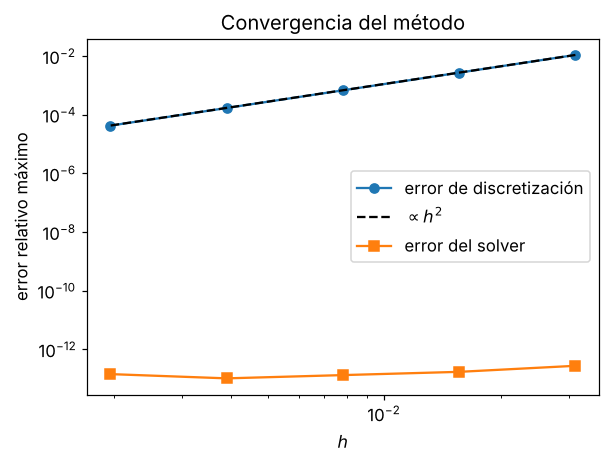

In [12]:
Ns = [32, 64, 128, 256, 512]
err_solver, err_disc = [], []
for N in Ns:
    out = correr(N, metodo=2, tol=1e-10, modo=0)
    err_solver.append(float(re.search(r"discreta exacta \(solver\):\s+([\d.e+-]+)", out).group(1)))
    err_disc.append(float(re.search(r"~h\^2\):\s+([\d.e+-]+)", out).group(1)))

h = 1/np.array(Ns)
print(" N    error solver   error discretización   cociente")
for i, N in enumerate(Ns):
    q = err_disc[i-1]/err_disc[i] if i else float("nan")
    print(f"{N:4d}   {err_solver[i]:.2e}       {err_disc[i]:.3e}           {q:.2f}")

fig, ax = plt.subplots(figsize=(6, 4.2))
ax.loglog(h, err_disc, "o-", label="error de discretización")
ax.loglog(h, err_disc[0]*(h/h[0])**2, "k--", label=r"$\propto h^2$")
ax.loglog(h, err_solver, "s-", label="error del solver")
ax.set_xlabel("$h$"); ax.set_ylabel("error relativo máximo"); ax.legend()
ax.set_title("Convergencia del método")
ax.xaxis.set_minor_formatter(plt.NullFormatter())
guardar(fig, "convergencia"); plt.show()

**Qué muestra.** El error de discretización (círculos) sigue la recta $\propto h^2$: al duplicar $N$ baja exactamente 4 veces, como corresponde a un esquema de segundo orden. El error del solver (cuadrados) queda en $10^{-15}$–$10^{-13}$, es decir, la iteración resuelve el sistema discreto hasta la precisión de la máquina; todo el error frente a la física viene de la discretización.

## 4. Número de iteraciones frente a la teoría

Para Jacobi, cada modo $e_{p,q}$ del error se multiplica en cada iteración por $\tfrac12[\cos(2\pi p h)+\cos(2\pi q h)]$ (caso periódico). Excluyendo el modo cero, el más lento es $(1,0)$, con $\rho_J = \cos^2(\pi h)\approx 1-\pi^2h^2$ [15]:

$$
k_{\text{Jacobi}} \approx \frac{\ln(1/\varepsilon)}{\pi^2h^2} \propto N^2,
\qquad
k_{\text{GS}} \approx \tfrac12 k_{\text{Jacobi}},
\qquad
k_{\text{SOR}} \propto N .
$$

La fuente es un campo gaussiano aleatorio, que excita todos los modos.

N=  32  Jacobi    1900 (pred.     1911)  GS    1000  SOR   100
N=  64  Jacobi    7200 (pred.     7645)  GS    3700  SOR   200
N= 128  Jacobi   26800 (pred.    30579)  GS   13700  SOR   400
N= 256  Jacobi  114600 (pred.   122317)  GS   58500  SOR   800


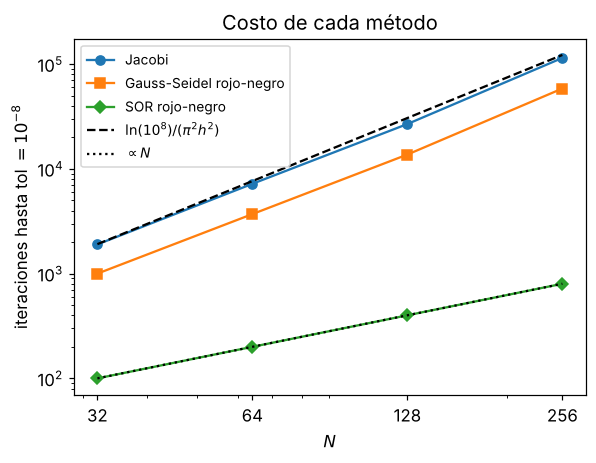

In [13]:
def generar_delta(N, n_s=-1.0, sigma=1.0, semilla=42):
    # Campo gaussiano periódico con P(k) ∝ k^n_s exp(-(k/kc)^2).
    # Receta: ruido blanco -> FFT -> multiplicar por sqrt(P(k)) -> FFT inversa.
    rng = np.random.default_rng(semilla)
    k1 = 2*np.pi*np.fft.fftfreq(N, d=1.0/N)
    kx, ky = np.meshgrid(k1, k1, indexing="xy")
    k = np.sqrt(kx**2 + ky**2); k[0, 0] = 1.0
    kc = 2*np.pi*N/8                                 # corte suave: evita ruido de malla
    P = k**n_s * np.exp(-(k/kc)**2); P[0, 0] = 0.0   # <delta> = 0
    delta = np.fft.ifft2(np.fft.fft2(rng.normal(size=(N, N))) * np.sqrt(P)).real
    delta *= sigma/delta.std()
    with open(os.path.join(TRABAJO, "delta.bin"), "wb") as f:   # mismo formato que el código C
        np.array([N, N, 1, 8], dtype=np.int32).tofile(f)
        delta.astype(np.float64).tofile(f)
    return delta

metodos = [(0, "Jacobi"), (1, "Gauss-Seidel rojo-negro"), (2, "SOR rojo-negro")]
Ns_it = [32, 64, 128, 256]
iters = {nombre: [] for _, nombre in metodos}
for N in Ns_it:
    generar_delta(N)
    for m, nombre in metodos:
        out = correr(N, metodo=m, tol=1e-8, modo=1)
        iters[nombre].append(int(re.search(r"Iteraciones: (\d+)", out).group(1)))

Na = np.array(Ns_it)
pred = np.log(1e8)/(np.pi**2/Na**2)
for i, N in enumerate(Ns_it):
    print(f"N={N:4d}  Jacobi {iters['Jacobi'][i]:7d} (pred. {pred[i]:8.0f})  "
          f"GS {iters['Gauss-Seidel rojo-negro'][i]:7d}  SOR {iters['SOR rojo-negro'][i]:5d}")

fig, ax = plt.subplots(figsize=(6, 4.2))
for nombre, mk in zip(iters, "osD"):
    ax.loglog(Na, iters[nombre], mk + "-", label=nombre)
ax.loglog(Na, pred, "k--", label=r"$\ln(10^8)/(\pi^2h^2)$")
ax.loglog(Na, iters["SOR rojo-negro"][0]*Na/Na[0], "k:", label=r"$\propto N$")
ax.set_xlabel("$N$"); ax.set_ylabel("iteraciones hasta tol $=10^{-8}$"); ax.legend(fontsize=9)
ax.set_title("Costo de cada método")
ax.xaxis.set_minor_formatter(plt.NullFormatter()); ax.set_xticks(Ns_it, [str(n) for n in Ns_it])
guardar(fig, "iteraciones"); plt.show()

**Qué muestra.** Jacobi (círculos) sigue la predicción $\propto N^2$ (línea discontinua); Gauss-Seidel rojo-negro necesita la mitad, porque su factor de contracción es $\rho_J^2$; SOR crece solo $\propto N$ (línea punteada). Con $N=256$, SOR necesita unas 140 veces menos iteraciones que Jacobi. El trabajo total es iteraciones × $N^2$ puntos, así que Jacobi cuesta $\sim N^4$ y SOR $\sim N^3$; multigrid llegaría a $\sim N^2$ [14].

## 5. Campo cosmológico: densidad, potencial y espectros

Resolvemos con SOR para un campo gaussiano en $N = 256$ y comparamos con la solución espectral del **mismo** problema discreto: en Fourier, el laplaciano de 5 puntos es diagonal con autovalor $\lambda_{\mathbf k} = -\tfrac{4}{h^2}\left[\sin^2\tfrac{k_xh}{2} + \sin^2\tfrac{k_yh}{2}\right]$ [4].

In [14]:
N, Om, a = 256, 0.3, 1.0
generar_delta(N)
print(correr(N, metodo=2, tol=1e-10, modo=1, Om=Om, a=a))

with open(os.path.join(TRABAJO, "salida_cpu.bin"), "rb") as f:
    nx, ny, nc, nb = (int(v) for v in np.fromfile(f, dtype=np.int32, count=4))  # int(): evita overflow de int32
    phi, delta = np.fromfile(f, dtype=np.float64).reshape(nc, ny, nx)

h = 1.0/N; pref = 1.5*Om/a
k1 = 2*np.pi*np.fft.fftfreq(N, d=h)
kx, ky = np.meshgrid(k1, k1, indexing="xy")
lam = -4/h**2*(np.sin(kx*h/2)**2 + np.sin(ky*h/2)**2); lam[0, 0] = 1.0
phik = pref*np.fft.fft2(delta - delta.mean())/lam; phik[0, 0] = 0.0
phi_fft = np.fft.ifft2(phik).real
print(f"Diferencia relativa máxima iterativo vs FFT: {np.abs(phi-phi_fft).max()/np.abs(phi_fft).max():.2e}")

Poisson comóvil 2D periódico: N = 256, método = SOR rojo-negro (w = 1.965884), tol = 1.0e-10, Om = 0.300, a = 1.000, <delta> = 6.06e-16
Iteraciones: 900, residuo relativo = 3.044e-11
Tiempo de cómputo: 0.163 s (0.181 ms por iteración)

Diferencia relativa máxima iterativo vs FFT: 8.03e-13


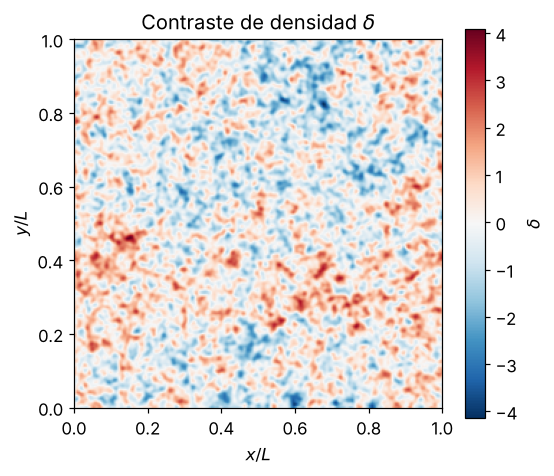

In [15]:
fig, ax = plt.subplots(figsize=(5.4, 4.6))
im = ax.imshow(delta, origin="lower", extent=[0, 1, 0, 1], cmap="RdBu_r")
plt.colorbar(im, ax=ax, label=r"$\delta$")
ax.set_xlabel(r"$x/L$"); ax.set_ylabel(r"$y/L$"); ax.set_title(r"Contraste de densidad $\delta$")
guardar(fig, "delta"); plt.show()

**Qué muestra.** Un campo gaussiano aleatorio con $P(k)\propto k^{-1}$ y $\sigma_\delta = 1$: regiones sobredensas (rojo) y subdensas (azul) en todas las escalas hasta el corte. Es la fuente $\delta$ que recibe el solver; en una simulación vendría del depósito de partículas.

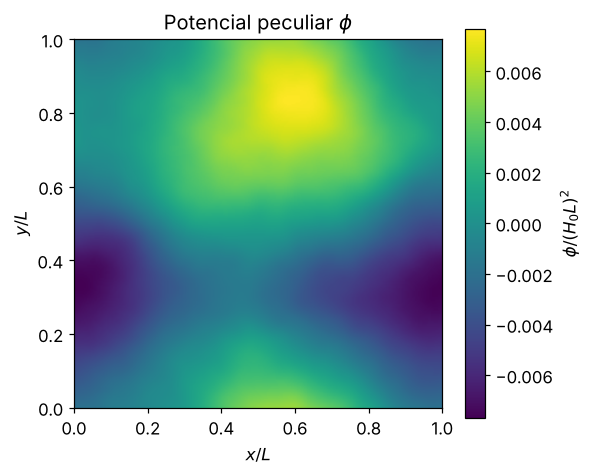

In [16]:
fig, ax = plt.subplots(figsize=(5.4, 4.6))
im = ax.imshow(phi, origin="lower", extent=[0, 1, 0, 1], cmap="viridis")
plt.colorbar(im, ax=ax, label=r"$\phi/(H_0L)^2$")
ax.set_xlabel(r"$x/L$"); ax.set_ylabel(r"$y/L$"); ax.set_title(r"Potencial peculiar $\phi$")
guardar(fig, "potencial"); plt.show()

**Qué muestra.** El potencial que genera ese campo. Es mucho más suave que $\delta$ porque Poisson divide por $k^2$ en Fourier: las escalas pequeñas quedan suprimidas y dominan las ondulaciones del tamaño de la caja. Las zonas oscuras son pozos de potencial ($\phi<0$), hacia donde fluye la materia [1].

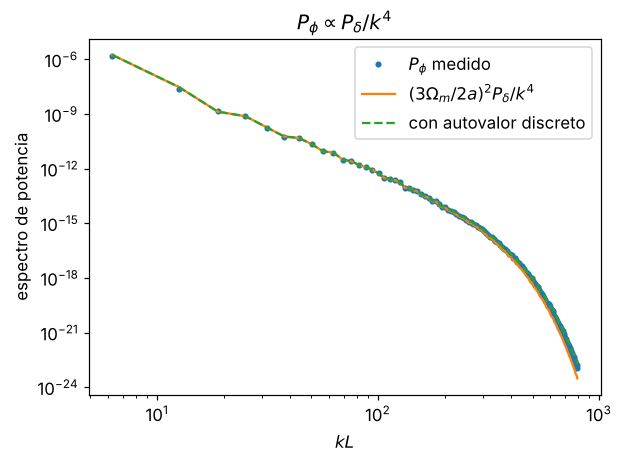

In [17]:
kmod = np.sqrt(kx**2 + ky**2)
bordes = np.arange(0.5, N//2, 1.0)*2*np.pi
idx = np.digitize(kmod.ravel(), bordes)
def espectro(campo):
    p = (np.abs(np.fft.fft2(campo))**2/float(N)**4).ravel()
    return np.array([p[idx == i].mean() for i in range(1, len(bordes))])
kc = 0.5*(bordes[1:] + bordes[:-1])
Pd, Pp = espectro(delta), espectro(phi)
P_cont = pref**2*Pd/kc**4
P_disc = pref**2*Pd/(4*N**2*np.sin(kc/(2*N))**2)**2

fig, ax = plt.subplots(figsize=(6, 4.2))
ax.loglog(kc, Pp, ".", label=r"$P_\phi$ medido")
ax.loglog(kc, P_cont, "-", label=r"$(3\Omega_m/2a)^2P_\delta/k^4$")
ax.loglog(kc, P_disc, "--", label="con autovalor discreto")
ax.set_xlabel(r"$kL$"); ax.set_ylabel("espectro de potencia"); ax.legend()
ax.set_title(r"$P_\phi \propto P_\delta/k^4$")
guardar(fig, "espectros"); plt.show()

**Qué muestra.** El espectro del potencial medido (puntos) sigue la predicción de Poisson $P_\phi = (3\Omega_m/2a)^2P_\delta/k^4$ [3]. En $k$ alto se separa levemente de $k^{-4}$ porque el laplaciano discreto tiene autovalor $\tfrac{4}{h^2}\sin^2(kh/2) < k^2$; con el autovalor discreto (línea discontinua) el acuerdo es completo. La diferencia con la solución FFT es $\sim10^{-12}$.

## 6. Para qué sirve: simulación *particle-mesh* 2D

Una simulación cosmológica de N-cuerpos es una solución Monte Carlo de Vlasov–Poisson [2, 4]. En cada paso:

1. **Depósito CIC**: cada partícula reparte su masa entre las 4 celdas vecinas, lo que da $\delta(\mathbf x)$ [4].
2. **Poisson comóvil**, que da $\phi$ (aquí con FFT para que sea rápido; es el paso que el proyecto acelera en GPU).
3. **Fuerza** $\mathbf g = -\nabla\phi$ con diferencias centradas, interpolada a las partículas con CIC.
4. **Leapfrog KDK** usando $a$ como tiempo. Con el momento $\mathbf p = a^2\dot{\mathbf x}$ y $dt = da/(aH)$ [5]:

$$
\frac{d\mathbf p}{da} = -\frac{\nabla\phi}{aH},\qquad \frac{d\mathbf x}{da} = \frac{\mathbf p}{a^3H},\qquad H = H_0\,a^{-3/2}\ \ (\text{EdS}).
$$

**Condiciones iniciales de Zel'dovich** [18]: $\mathbf x = \mathbf q + D(a)\,\boldsymbol\psi(\mathbf q)$ con $\delta = -\nabla\cdot\boldsymbol\psi$, es decir $\hat{\boldsymbol\psi}_{\mathbf k} = i\mathbf k\,\hat\delta_{\mathbf k}/k^2$, y $D = a$ en Einstein–de Sitter.

Es un modelo de juguete: dinámica 2D con los coeficientes de 3D. El algoritmo es el de GADGET o RAMSES [5, 6].

In [18]:
Ng = Np = 256
rng = np.random.default_rng(3)
k1 = 2*np.pi*np.fft.fftfreq(Ng, 1/Ng)
KX, KY = np.meshgrid(k1, k1, indexing="ij"); K2 = KX**2 + KY**2; K2[0, 0] = 1
P = np.sqrt(K2)**-1.0*np.exp(-K2/(2*np.pi*40)**2); P[0, 0] = 0
dk = np.fft.fft2(rng.normal(size=(Ng, Ng)))*np.sqrt(P)
sigma_lin = 0.9
dk *= sigma_lin/np.fft.ifft2(dk).real.std()     # sigma lineal en a = 1

psx = np.fft.ifft2(1j*KX*dk/K2).real; psy = np.fft.ifft2(1j*KY*dk/K2).real
q = (np.arange(Np) + 0.5)/Np; QX, QY = np.meshgrid(q, q, indexing="ij")
H = lambda a: a**-1.5
a = 0.02
x = (QX + a*psx) % 1; y = (QY + a*psy) % 1
px = a**2*(a*H(a))*psx; py = a**2*(a*H(a))*psy

def pesos(x, y):
    fx = x*Ng - 0.5; fy = y*Ng - 0.5
    i = np.floor(fx).astype(int); j = np.floor(fy).astype(int)
    return i, j, fx - i, fy - j

def cic(x, y):
    g = np.zeros((Ng, Ng)); i, j, tx, ty = pesos(x, y)
    for di, wx in ((0, 1 - tx), (1, tx)):
        for dj, wy in ((0, 1 - ty), (1, ty)):
            np.add.at(g, ((i + di) % Ng, (j + dj) % Ng), wx*wy)
    return g/g.mean() - 1

def interp(F, x, y):
    i, j, tx, ty = pesos(x, y); out = 0
    for di, wx in ((0, 1 - tx), (1, tx)):
        for dj, wy in ((0, 1 - ty), (1, ty)):
            out = out + F[(i + di) % Ng, (j + dj) % Ng]*wx*wy
    return out

lam = -(4*Ng**2)*(np.sin(KX/(2*Ng))**2 + np.sin(KY/(2*Ng))**2); lam[0, 0] = 1
def fuerza(x, y, a):
    d = cic(x, y)
    phik = 1.5/a*np.fft.fft2(d)/lam; phik[0, 0] = 0     # <- Poisson comóvil (Om = 1)
    phi = np.fft.ifft2(phik).real
    gx = -(np.roll(phi, -1, 0) - np.roll(phi, 1, 0))*Ng/2
    gy = -(np.roll(phi, -1, 1) - np.roll(phi, 1, 1))*Ng/2
    return interp(gx, x, y), interp(gy, x, y), d, phi

hist_a, hist_sd, hist_sp, snaps = [], [], [], {}
da = 0.004; t0 = time.time()
gx, gy, d, phi_pm = fuerza(x, y, a)
while a < 1.0 - 1e-9:
    hist_a.append(a); hist_sd.append(d.std()); hist_sp.append(phi_pm.std())
    for ao in (0.1, 0.3):
        if abs(a - ao) < da/2: snaps[ao] = (x.copy(), y.copy(), phi_pm.copy())
    px += gx/(a*H(a))*da/2; py += gy/(a*H(a))*da/2                         # kick
    am = a + da/2
    x = (x + px/(am**3*H(am))*da) % 1; y = (y + py/(am**3*H(am))*da) % 1   # drift
    a += da
    gx, gy, d, phi_pm = fuerza(x, y, a)
    px += gx/(a*H(a))*da/2; py += gy/(a*H(a))*da/2                         # kick
hist_a.append(a); hist_sd.append(d.std()); hist_sp.append(phi_pm.std())
snaps[1.0] = (x, y, phi_pm)
print(f"{len(hist_a)} pasos, {time.time() - t0:.1f} s")

# Resultados para otras figuras (presentación)
np.savez(os.path.join(TRABAJO, "resultados.npz"), delta=delta, phi=phi, kc=kc, Pp=Pp, P_cont=P_cont,
         P_disc=P_disc, h=h, Ns=Ns, err_disc=err_disc, err_solver=err_solver, Ns_it=Ns_it,
         it_j=iters["Jacobi"], it_gs=iters["Gauss-Seidel rojo-negro"], it_sor=iters["SOR rojo-negro"],
         hist_a=hist_a, hist_sd=hist_sd, hist_sp=hist_sp, sigma_lin=sigma_lin,
         **{f"snap{ao}_{c}": v for ao, s in snaps.items() for c, v in zip("xyp", s)})

246 pasos, 5.3 s


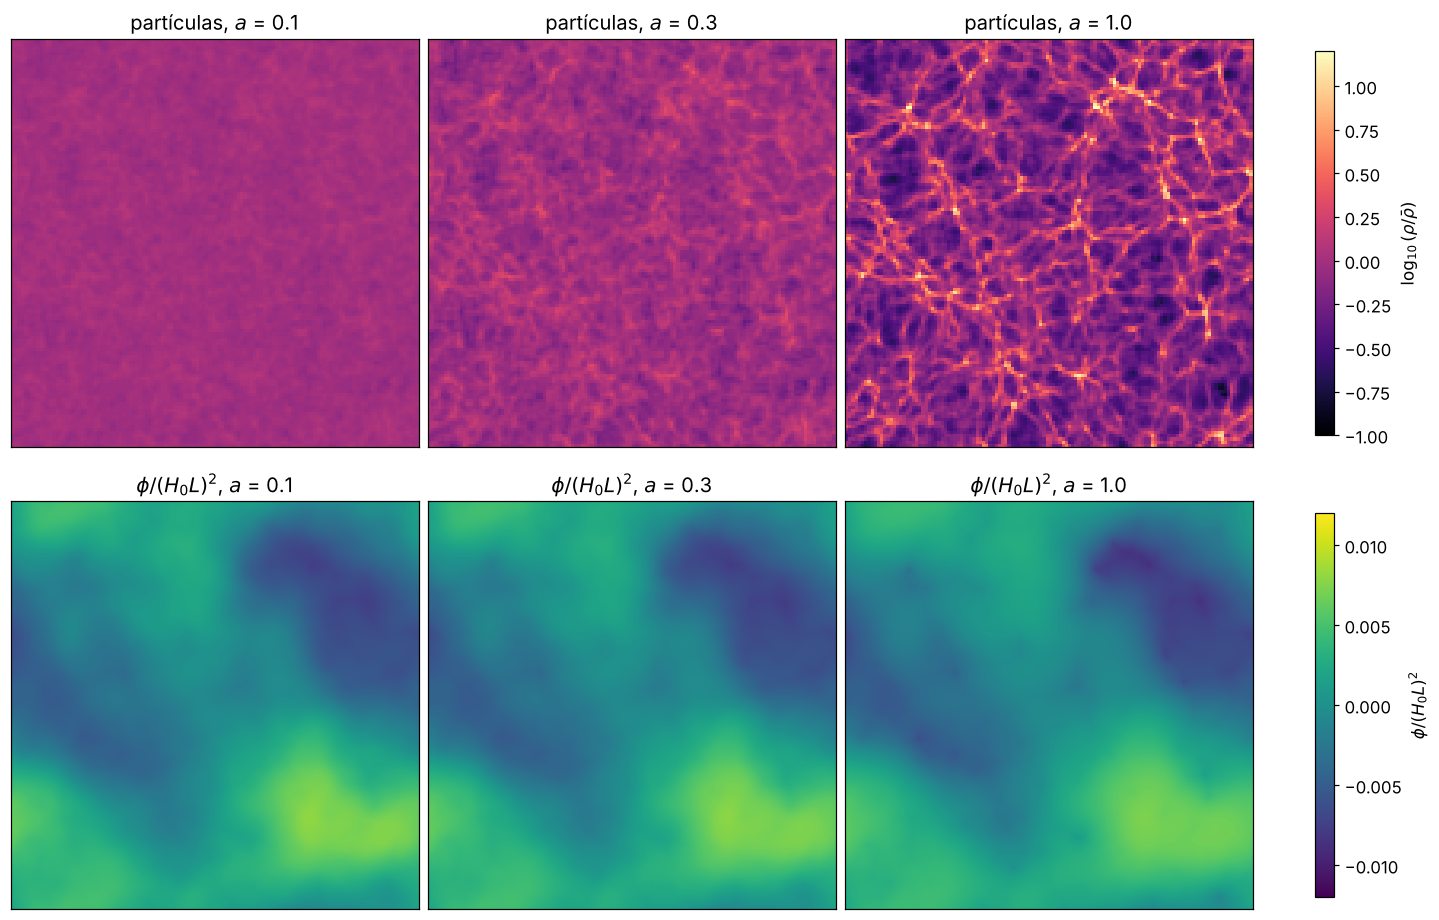

In [19]:
def densidad_particulas(X, Y, n=128):
    # Densidad de partículas con depósito CIC en una malla de n x n: log10(rho/rho_media)
    g = np.zeros((n, n)); fx = X.ravel()*n - 0.5; fy = Y.ravel()*n - 0.5
    i = np.floor(fx).astype(int); j = np.floor(fy).astype(int); tx = fx - i; ty = fy - j
    for di, wx in ((0, 1 - tx), (1, tx)):
        for dj, wy in ((0, 1 - ty), (1, ty)):
            np.add.at(g, ((i + di) % n, (j + dj) % n), wx*wy)
    return np.log10(np.clip(g/g.mean(), 0.1, None))

fig, ax = plt.subplots(2, 3, figsize=(13, 8.4), constrained_layout=True)
for c, ao in enumerate((0.1, 0.3, 1.0)):
    X, Y, ph = snaps[ao]
    imd = ax[0, c].imshow(densidad_particulas(X, Y).T, origin="lower", extent=[0, 1, 0, 1],
                          cmap="magma", vmin=-1, vmax=1.2)
    ax[0, c].set_title(f"partículas, $a$ = {ao}")
    imp = ax[1, c].imshow(ph.T, origin="lower", extent=[0, 1, 0, 1], cmap="viridis",
                          vmin=-0.012, vmax=0.012)
    ax[1, c].set_title(rf"$\phi/(H_0L)^2$, $a$ = {ao}")
    for A in ax[:, c]: A.set_xticks([]); A.set_yticks([])
fig.colorbar(imd, ax=ax[0, :], shrink=0.9, label=r"$\log_{10}(\rho/\bar\rho)$")
fig.colorbar(imp, ax=ax[1, :], shrink=0.9, label=r"$\phi/(H_0L)^2$")
guardar(fig, "pm_evolucion"); plt.show()

**Qué muestra.** Arriba, la densidad de partículas, $\log_{10}(\rho/\bar\rho)$ obtenida con depósito CIC, con el mapa de colores *magma*, el mismo que usa GRAMSES para la densidad [7]. En $a = 0.1$ la distribución es casi uniforme ($\rho\approx\bar\rho$ en todas partes). En $a = 0.3$ aparecen las primeras sobredensidades. En $a = 1$ se ve la **red cósmica**: filamentos, nodos donde se cruzan y vacíos. Los filamentos aparecen porque el colapso es anisótropo: en la aproximación de Zel'dovich la densidad es $\bar\rho/[(1-D\lambda_1)(1-D\lambda_2)]$ y colapsa primero la dirección del autovalor mayor [18].

Abajo, el potencial en las mismas épocas: los tres mapas son casi iguales, y sus pozos (zonas oscuras) coinciden con los nodos y filamentos de arriba.

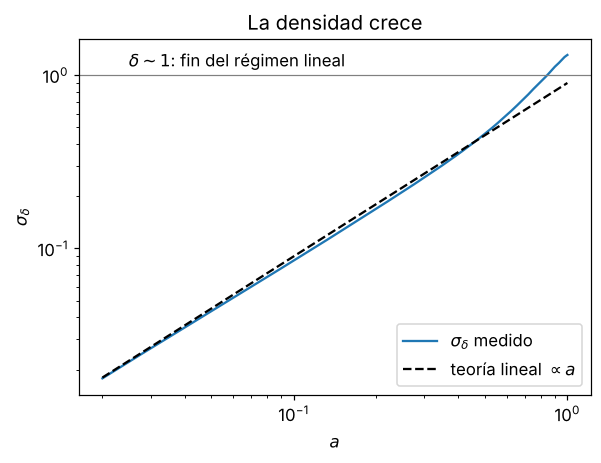

In [20]:
A = np.array(hist_a)
fig, ax = plt.subplots(figsize=(6, 4.2))
ax.loglog(A, hist_sd, label=r"$\sigma_\delta$ medido")
ax.loglog(A, sigma_lin*A, "k--", label=r"teoría lineal $\propto a$")
ax.axhline(1, color="gray", lw=0.8); ax.text(0.025, 1.12, r"$\delta\sim1$: fin del régimen lineal")
ax.set_xlabel("$a$"); ax.set_ylabel(r"$\sigma_\delta$"); ax.legend(loc="lower right")
ax.set_title("La densidad crece")
guardar(fig, "crecimiento_densidad"); plt.show()

**Qué muestra.** La desviación estándar de la densidad sigue la teoría lineal $\delta\propto a$ (recta de pendiente 1) hasta $\sigma_\delta\approx0.5$, confirmando $\ddot\delta + 2H\dot\delta = 4\pi G\bar\rho\,\delta$ [1, 3]. Después crece **más rápido**: es el régimen no lineal, donde los términos $\delta\,\mathbf v$ y $(\mathbf v\cdot\nabla)\mathbf v$ que se descartaron al linealizar dejan de ser pequeños, y donde la simulación es la única herramienta [2].

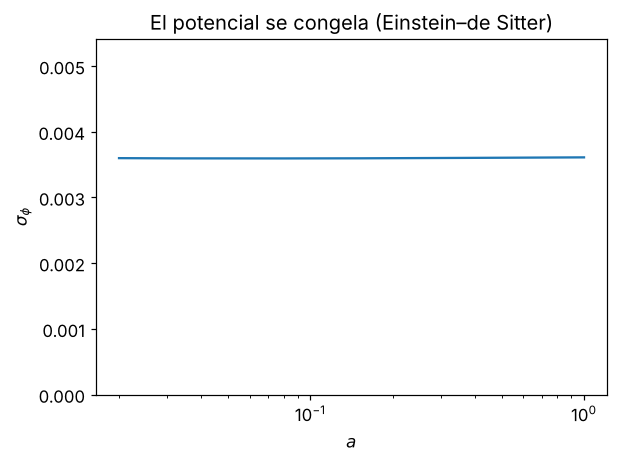

In [21]:
fig, ax = plt.subplots(figsize=(6, 4.2))
ax.semilogx(A, hist_sp)
ax.set_ylim(0, 1.5*max(hist_sp))
ax.set_xlabel("$a$"); ax.set_ylabel(r"$\sigma_\phi$")
ax.set_title(r"El potencial se congela (Einstein–de Sitter)")
guardar(fig, "potencial_congelado"); plt.show()

**Qué muestra.** La dispersión del potencial es constante, $\sigma_\phi \approx 3.6\times10^{-3}$, de $a = 0.02$ a $a = 1$, como predice $\phi\propto a^2\bar\rho\,\delta\propto a^2 a^{-3}a$ [1]. Se mantiene incluso en el régimen no lineal, porque $\phi$ está dominado por escalas grandes, que siguen siendo lineales. Con energía oscura el crecimiento se frena y esta curva bajaría a bajo redshift: es el origen del efecto Sachs–Wolfe integrado [12].

## 7. Siguiente paso: CUDA

En Colab: *Entorno de ejecución → Cambiar tipo de entorno → GPU (T4)*, y luego `!nvcc --version`. La versión 1 porta los kernels `jacobi` y `media_iteracion_rb` (un thread por punto, índices periódicos), la reducción del residuo y `restar_promedio`, manteniendo `u`, `f` y `delta` en la GPU.

## Referencias

1. P. J. E. Peebles, *The Large-Scale Structure of the Universe*, Princeton University Press (1980).
2. E. Bertschinger, Simulations of structure formation in the universe, *ARA&A* **36**, 599 (1998). [DOI](https://doi.org/10.1146/annurev.astro.36.1.599)
3. S. Dodelson & F. Schmidt, *Modern Cosmology*, 2.ª ed., Academic Press (2020).
4. R. W. Hockney & J. W. Eastwood, *Computer Simulation Using Particles*, IOP (1988).
5. V. Springel, The cosmological simulation code GADGET-2, *MNRAS* **364**, 1105 (2005). [arXiv:astro-ph/0505010](https://arxiv.org/abs/astro-ph/0505010)
6. R. Teyssier, Cosmological hydrodynamics with adaptive mesh refinement, *A&A* **385**, 337 (2002). [arXiv:astro-ph/0111367](https://arxiv.org/abs/astro-ph/0111367)
7. C. Barrera-Hinojosa & B. Li, GRAMSES. Part I, *JCAP* **01** (2020) 007. [arXiv:1905.08890](https://arxiv.org/abs/1905.08890)
12. R. K. Sachs & A. M. Wolfe, *ApJ* **147**, 73 (1967). [DOI](https://doi.org/10.1086/148982)
14. W. L. Briggs, V. E. Henson & S. F. McCormick, *A Multigrid Tutorial*, 2.ª ed., SIAM (2000).
15. W. H. Press et al., *Numerical Recipes*, 3.ª ed., Cambridge University Press (2007), §20.5.
18. Ya. B. Zel'dovich, *A&A* **5**, 84 (1970).

La numeración sigue la lista completa del `README.md`.